# CUSTOMER PURCHASE PREDICTION - CLASSIFICATION MODELS

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
# Load the data ONE time (change the path if your file is elsewhere)
df = pd.read_excel("C:/Users/hp/Downloads/Data_Practical/customer_purchase_data.xlsx")
FILE_PATH = "customer_purchase_data.xlsx"
df = pd.read_excel(FILE_PATH, sheet_name="Data")   # sheet 'Data_Dictionary' is only documentation

print("Shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isna().sum())
print("\nTarget balance:\n", df["Purchased"].value_counts(normalize=True).round(3))

#1. DATA PREPROCESSING 
# Justification: Age (8) and Annual_Salary (15) have missing values; models such as
# Logistic Regression, SVM, KNN cannot handle NaN. We use the MEDIAN (robust to
# the salary outliers) - but it is fitted on TRAIN ONLY (below) to avoid data leakage.

df = df.drop_duplicates().reset_index(drop=True)      # no duplicates found, kept as a safe step

# Encode categorical variables
# Justification: Education has a natural order (School < Graduate < Postgraduate), so an
# ordinal encoding keeps that information; Gender is binary so 0/1 is enough.
df["Education_Level"] = df["Education"].map({"School": 0, "Graduate": 1, "Postgraduate": 2})
df["Gender_Male"] = (df["Gender"] == "Male").astype(int)

#  2. FEATURE ENGINEERING 
# Justification: new features capture relationships the raw columns do not show directly.
# NaN values are kept here; they propagate and are imputed after the split.
df["Log_Salary"] = np.log1p(df["Annual_Salary"])                     # reduces salary skew
df["Salary_per_Visit"] = df["Annual_Salary"] / df["Website_Visits"]  # income relative to engagement
df["Age_x_Visits"] = df["Age"] * df["Website_Visits"]                # engagement by age interaction

features = ["Age", "Annual_Salary", "Website_Visits", "Education_Level",
            "Gender_Male", "Log_Salary", "Salary_per_Visit", "Age_x_Visits"]
X = df[features]
y = df["Purchased"]

# Train / test split (stratified keeps the 63/37 class ratio in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

# Impute (fit on train only), then scale (fit on train only)
imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=features)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=features)

# Justification: Logistic Regression, KNN, SVM and Discriminant Analysis are sensitive to
# feature scale (distance / gradient based), so we standardise (mean 0, std 1).
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_imp)
X_test_sc = scaler.transform(X_test_imp)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}   # filled by each model, used in section 10

def evaluate(name, model, Xtr, Xte, show_report=True):
    """Fit-free helper: assumes model is already fitted. Stores and prints metrics."""
    pred = model.predict(Xte)
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(Xte)[:, 1]
    else:
        score = model.decision_function(Xte)
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC_AUC": roc_auc_score(y_test, score),
        "CV_Acc(train)": cross_val_score(model, Xtr, y_train, cv=cv).mean(),
    }
    print(f"\n===== {name} =====")
    print("Confusion matrix:\n", confusion_matrix(y_test, pred))
    if show_report:
        print(classification_report(y_test, pred, digits=3))

#  FEATURE Selection

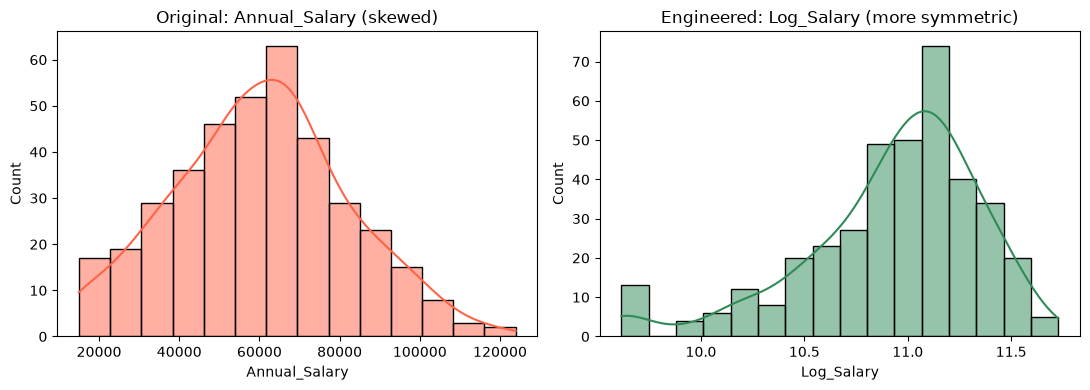

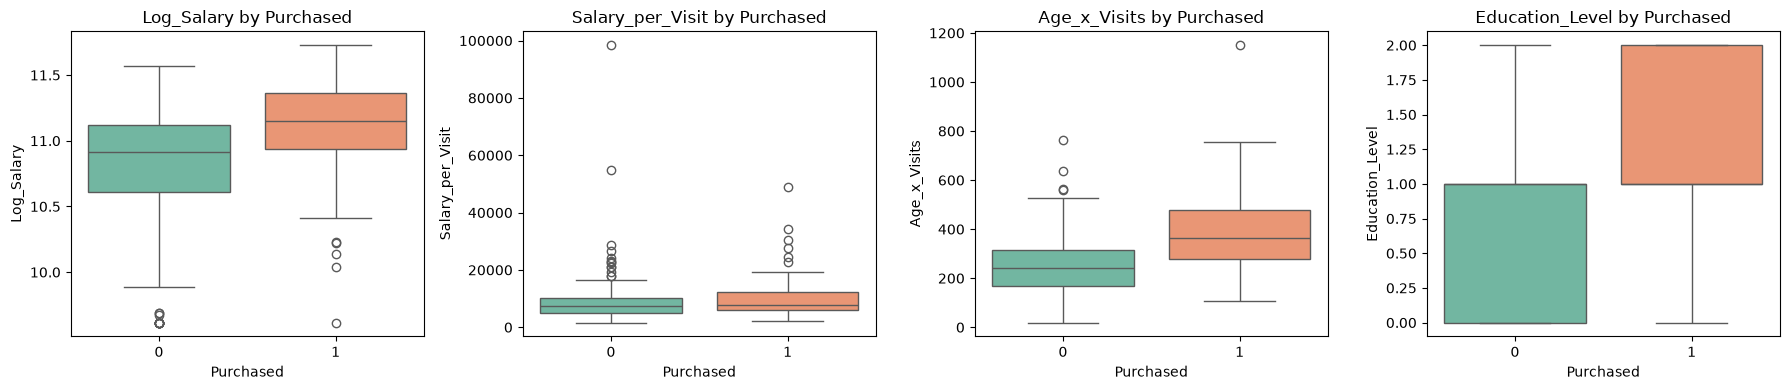

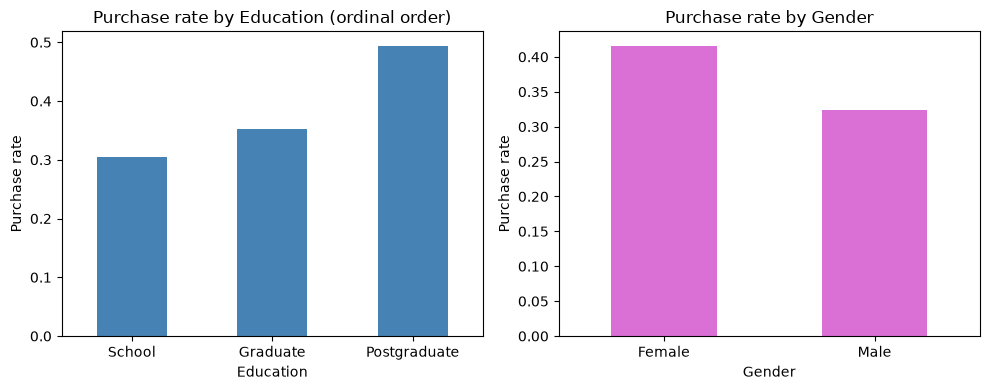

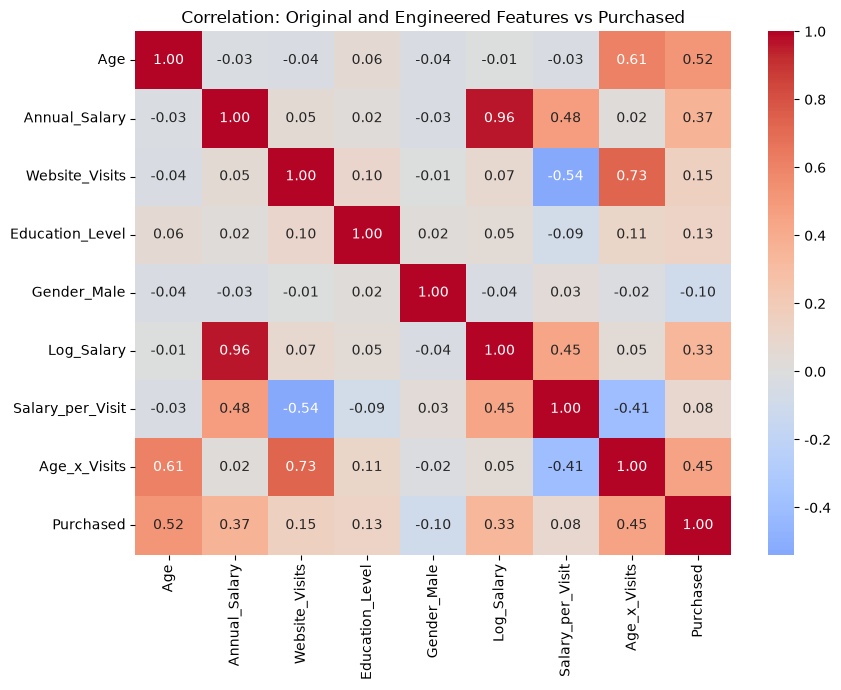

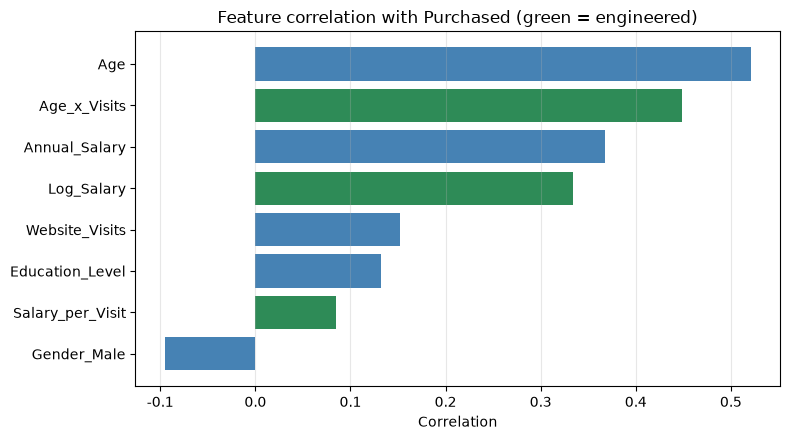

In [20]:
X = df[features]
y = df["Purchased"]
# Justification: graphs show WHY each new feature was created and whether it helps
# separate buyers (1) from non-buyers (0).

# (a) Before vs after: Annual_Salary is skewed, Log_Salary is more symmetric
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Annual_Salary"].dropna(), kde=True, ax=axes[0], color="tomato")
axes[0].set_title("Original: Annual_Salary (skewed)")
sns.histplot(df["Log_Salary"].dropna(), kde=True, ax=axes[1], color="seagreen")
axes[1].set_title("Engineered: Log_Salary (more symmetric)")
plt.tight_layout(); plt.show()

# (b) Engineered features by purchase outcome (clear separation = useful feature)
eng_feats = ["Log_Salary", "Salary_per_Visit", "Age_x_Visits", "Education_Level"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, eng_feats):
    sns.boxplot(x="Purchased", y=col, data=df, ax=ax, palette="Set2")
    ax.set_title(f"{col} by Purchased")
plt.tight_layout(); plt.show()

# (c) Purchase rate by education and gender (basis of the encodings)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df.groupby("Education")["Purchased"].mean().reindex(["School", "Graduate", "Postgraduate"]) \
  .plot(kind="bar", ax=axes[0], color="steelblue", rot=0)
axes[0].set_title("Purchase rate by Education (ordinal order)"); axes[0].set_ylabel("Purchase rate")
df.groupby("Gender")["Purchased"].mean().plot(kind="bar", ax=axes[1], color="orchid", rot=0)
axes[1].set_title("Purchase rate by Gender"); axes[1].set_ylabel("Purchase rate")
plt.tight_layout(); plt.show()

# (d) Correlation heat-map of original + engineered features with the target
plt.figure(figsize=(9, 7))
sns.heatmap(df[features + ["Purchased"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation: Original and Engineered Features vs Purchased")
plt.tight_layout(); plt.show()

# (e) Ranking: correlation of every feature with the target
corr_target = df[features + ["Purchased"]].corr()["Purchased"].drop("Purchased").sort_values()
plt.figure(figsize=(8, 4.5))
colors = ["seagreen" if f in ["Log_Salary", "Salary_per_Visit", "Age_x_Visits"] else "steelblue"
          for f in corr_target.index]
plt.barh(corr_target.index, corr_target.values, color=colors)
plt.title("Feature correlation with Purchased (green = engineered)")
plt.xlabel("Correlation"); plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

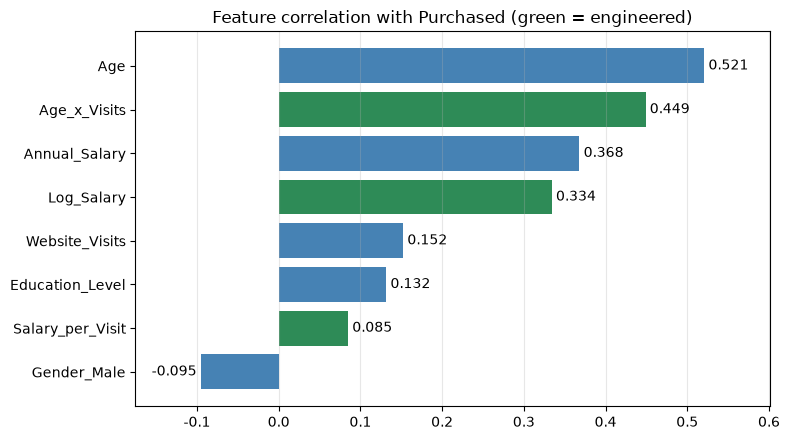

In [22]:
# (e) Ranking: correlation of every feature with the target
corr_target = df[features + ["Purchased"]].corr()["Purchased"].drop("Purchased").sort_values()
plt.figure(figsize=(8, 4.5))
colors = ["seagreen" if f in ["Log_Salary", "Salary_per_Visit", "Age_x_Visits"] else "steelblue"
          for f in corr_target.index]
bars = plt.barh(corr_target.index, corr_target.values, color=colors)
plt.bar_label(bars, fmt="%.3f", padding=3)           # ranked value printed on each bar
plt.xlim(min(corr_target.min() - 0.08, -0.05), corr_target.max() + 0.08)
plt.title("Feature correlation with Purchased (green = engineered)")
plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

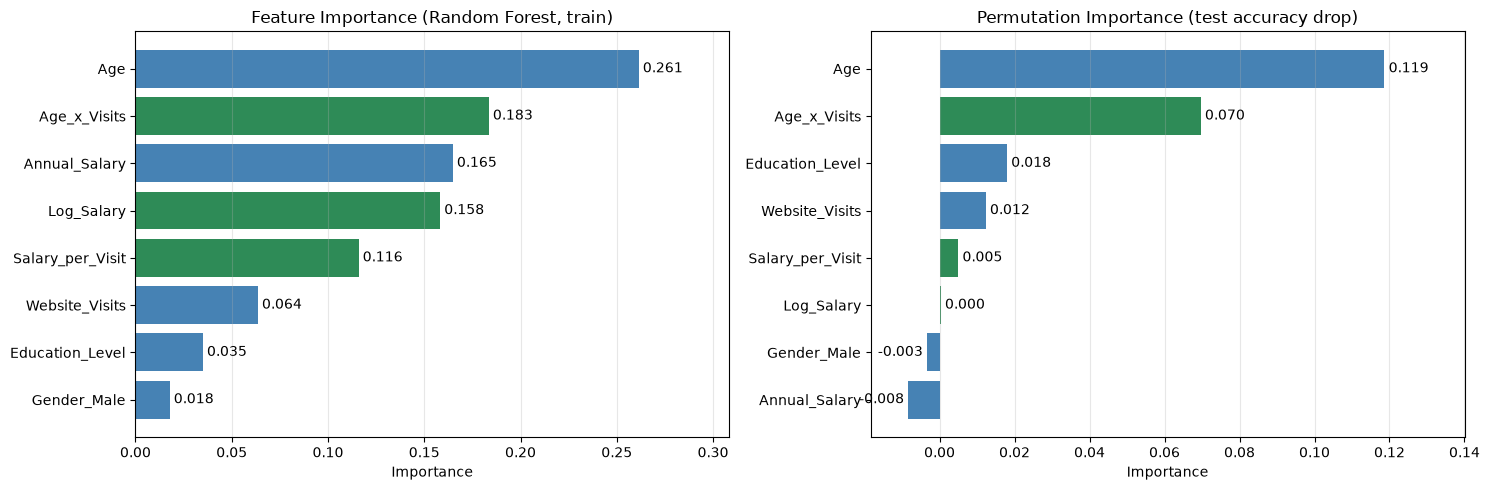

Feature importance ranking (Random Forest):
 Age                 0.261
Age_x_Visits        0.183
Annual_Salary       0.165
Log_Salary          0.158
Salary_per_Visit    0.116
Website_Visits      0.064
Education_Level     0.035
Gender_Male         0.018
dtype: float64


In [23]:
# Justification: a Random Forest measures how much each feature helps to separate buyers
# from non-buyers (Gini importance, fitted on TRAIN only). Permutation importance
# double-checks it on the TEST set: it shows how much accuracy drops when a feature
# is shuffled. Green = engineered features, blue = original features.
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)
rf.fit(X_train_imp, y_train)
imp_rf = pd.Series(rf.feature_importances_, index=features).sort_values()

perm = permutation_importance(rf, X_test_imp, y_test, n_repeats=30,
                              random_state=RANDOM_STATE, scoring="accuracy")
imp_perm = pd.Series(perm.importances_mean, index=features).sort_values()

engineered = ["Log_Salary", "Salary_per_Visit", "Age_x_Visits"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, imp, title in zip(axes, [imp_rf, imp_perm],
                          ["Feature Importance (Random Forest, train)",
                           "Permutation Importance (test accuracy drop)"]):
    bars = ax.barh(imp.index, imp.values,
                   color=["seagreen" if f in engineered else "steelblue" for f in imp.index])
    ax.bar_label(bars, fmt="%.3f", padding=3)        # ranked value printed on each bar
    ax.set_xlim(min(imp.min() - 0.01, 0), imp.max() * 1.18)
    ax.set_title(title); ax.set_xlabel("Importance"); ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()
print("Feature importance ranking (Random Forest):\n",
      imp_rf.sort_values(ascending=False).round(3))

# LOGISTIC REGRESSION

In [9]:
# Justification: simple, fast, interpretable baseline for a binary target; gives
# probabilities and coefficients showing each feature's effect on purchase.
# Assumes a roughly linear relationship between features and log-odds.
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_sc, y_train)
evaluate("Logistic Regression", log_reg, X_train_sc, X_test_sc)
print("Coefficients (standardised):\n",
      pd.Series(log_reg.coef_[0], index=features).sort_values(ascending=False).round(3))


===== Logistic Regression =====
Confusion matrix:
 [[57  6]
 [11 26]]
              precision    recall  f1-score   support

           0      0.838     0.905     0.870        63
           1      0.812     0.703     0.754        37

    accuracy                          0.830       100
   macro avg      0.825     0.804     0.812       100
weighted avg      0.829     0.830     0.827       100

Coefficients (standardised):
 Age                 1.828
Annual_Salary       1.735
Website_Visits      0.540
Education_Level     0.307
Age_x_Visits        0.039
Salary_per_Visit    0.035
Gender_Male        -0.032
Log_Salary         -0.283
dtype: float64


# NAIVE BAYES

In [10]:
# Justification: probabilistic model using Bayes' theorem with the "naive" assumption
# that features are independent given the class. Gaussian version fits continuous
# data. Very fast, works with small data, but our engineered features are correlated,
# which violates the independence assumption and may limit performance.
nb = GaussianNB()
nb.fit(X_train_sc, y_train)
evaluate("Naive Bayes", nb, X_train_sc, X_test_sc)


===== Naive Bayes =====
Confusion matrix:
 [[55  8]
 [12 25]]
              precision    recall  f1-score   support

           0      0.821     0.873     0.846        63
           1      0.758     0.676     0.714        37

    accuracy                          0.800       100
   macro avg      0.789     0.774     0.780       100
weighted avg      0.797     0.800     0.797       100



# K-NEAREST NEIGHBORS

In [11]:
# Justification: non-parametric, classifies by majority vote of the k closest customers.
# Needs scaled data (done). k is tuned by cross-validation: small k = low bias/high
# variance (overfits); large k = high bias/low variance (underfits).
knn_grid = GridSearchCV(KNeighborsClassifier(),
                        {"n_neighbors": list(range(3, 32, 2)), "weights": ["uniform", "distance"]},
                        cv=cv, scoring="accuracy")
knn_grid.fit(X_train_sc, y_train)
knn = knn_grid.best_estimator_
print("\nBest KNN params:", knn_grid.best_params_)
evaluate("K-NN", knn, X_train_sc, X_test_sc)



Best KNN params: {'n_neighbors': 27, 'weights': 'distance'}

===== K-NN =====
Confusion matrix:
 [[57  6]
 [16 21]]
              precision    recall  f1-score   support

           0      0.781     0.905     0.838        63
           1      0.778     0.568     0.656        37

    accuracy                          0.780       100
   macro avg      0.779     0.736     0.747       100
weighted avg      0.780     0.780     0.771       100



#  SUPPORT VECTOR MACHINE (LINEAR) 

In [12]:
# Justification: finds the maximum-margin straight line/hyperplane separating buyers
# from non-buyers. C controls the margin/error trade-off and is tuned by CV.
svm_grid = GridSearchCV(SVC(kernel="linear", probability=True, random_state=RANDOM_STATE),
                        {"C": [0.01, 0.1, 1, 10, 100]}, cv=cv, scoring="accuracy")
svm_grid.fit(X_train_sc, y_train)
svm_linear = svm_grid.best_estimator_
print("\nBest linear SVM params:", svm_grid.best_params_)
evaluate("SVM (Linear)", svm_linear, X_train_sc, X_test_sc)


Best linear SVM params: {'C': 1}

===== SVM (Linear) =====
Confusion matrix:
 [[58  5]
 [13 24]]
              precision    recall  f1-score   support

           0      0.817     0.921     0.866        63
           1      0.828     0.649     0.727        37

    accuracy                          0.820       100
   macro avg      0.822     0.785     0.796       100
weighted avg      0.821     0.820     0.814       100



# DECISION TREE (BIAS-VARIANCE)

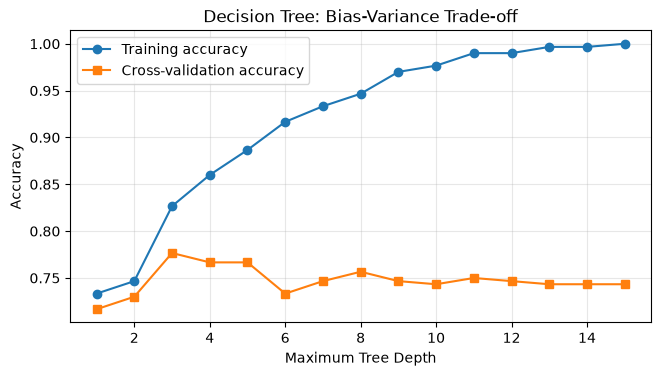


Best Decision Tree Parameters:
{'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 5}

Best Cross-Validation Accuracy:
0.8

===== Decision Tree =====
Confusion matrix:
 [[60  3]
 [20 17]]
              precision    recall  f1-score   support

           0      0.750     0.952     0.839        63
           1      0.850     0.459     0.596        37

    accuracy                          0.770       100
   macro avg      0.800     0.706     0.718       100
weighted avg      0.787     0.770     0.749       100



In [14]:

# Reset Matplotlib font configuration to avoid missing-font errors
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.sans-serif": ["DejaVu Sans"],
    "font.enable_last_resort": False,
    "axes.unicode_minus": False
})

# Decision Tree: Bias-Variance Trade-off
# Justification:
# Decision trees capture nonlinear relationships and interactions.
# They do not require feature scaling.
# Limiting tree depth helps prevent overfitting.

depths = range(1, 16)
train_acc, test_cv_acc = [], []

for d in depths:
    t = DecisionTreeClassifier(
        max_depth=d,
        random_state=RANDOM_STATE
    )

    t.fit(X_train_imp, y_train)

    train_acc.append(t.score(X_train_imp, y_train))

    test_cv_acc.append(
        cross_val_score(
            t, X_train_imp, y_train,
            cv=cv, scoring="accuracy"
        ).mean()
    )

# Plot bias-variance trade-off
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(depths, train_acc, "o-", label="Training accuracy")
ax.plot(depths, test_cv_acc, "s-", label="Cross-validation accuracy")

ax.set_xlabel("Maximum Tree Depth")
ax.set_ylabel("Accuracy")
ax.set_title("Decision Tree: Bias-Variance Trade-off")
ax.legend()
ax.grid(alpha=0.3)

# Avoid tight_layout() to bypass the reported rendering issue
fig.subplots_adjust(left=0.12, right=0.95, bottom=0.15, top=0.88)

plt.show()
plt.close()

# Hyperparameter tuning using GridSearchCV
tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    {
        "max_depth": [2, 3, 4, 5, 6, 8],
        "min_samples_leaf": [1, 5, 10, 20],
        "criterion": ["gini", "entropy"]
    },
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

tree_grid.fit(X_train_imp, y_train)

# Best Decision Tree model
tree = tree_grid.best_estimator_

print("\nBest Decision Tree Parameters:")
print(tree_grid.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(tree_grid.best_score_, 4))

# Evaluate final model on training and test datasets
evaluate("Decision Tree", tree, X_train_imp, X_test_imp)


# DISCRIMINANT ANALYSIS

In [15]:
# Justification: LDA assumes each class is Gaussian with the SAME covariance (linear
# boundary); QDA allows a different covariance per class (curved boundary) but needs
# more data. Comparing both shows whether a linear or quadratic boundary fits better.
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_sc, y_train)
evaluate("LDA", lda, X_train_sc, X_test_sc)

qda = QuadraticDiscriminantAnalysis(reg_param=0.5)  # regularised: engineered features are collinear
qda.fit(X_train_sc, y_train)
evaluate("QDA", qda, X_train_sc, X_test_sc)



===== LDA =====
Confusion matrix:
 [[57  6]
 [10 27]]
              precision    recall  f1-score   support

           0      0.851     0.905     0.877        63
           1      0.818     0.730     0.771        37

    accuracy                          0.840       100
   macro avg      0.834     0.817     0.824       100
weighted avg      0.839     0.840     0.838       100


===== QDA =====
Confusion matrix:
 [[55  8]
 [ 9 28]]
              precision    recall  f1-score   support

           0      0.859     0.873     0.866        63
           1      0.778     0.757     0.767        37

    accuracy                          0.830       100
   macro avg      0.819     0.815     0.817       100
weighted avg      0.829     0.830     0.830       100



# KERNEL SVM (RBF)

In [16]:
# Justification: the RBF kernel maps data to a higher dimension so the SVM can draw a
# NON-linear boundary. C (error penalty) and gamma (reach of one point) are tuned by CV
# to balance bias and variance.
ksvm_grid = GridSearchCV(SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
                         {"C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1, 1]},
                         cv=cv, scoring="accuracy")
ksvm_grid.fit(X_train_sc, y_train)
kernel_svm = ksvm_grid.best_estimator_
print("\nBest kernel SVM params:", ksvm_grid.best_params_)
evaluate("Kernel SVM (RBF)", kernel_svm, X_train_sc, X_test_sc)


Best kernel SVM params: {'C': 10, 'gamma': 0.01}

===== Kernel SVM (RBF) =====
Confusion matrix:
 [[58  5]
 [13 24]]
              precision    recall  f1-score   support

           0      0.817     0.921     0.866        63
           1      0.828     0.649     0.727        37

    accuracy                          0.820       100
   macro avg      0.822     0.785     0.796       100
weighted avg      0.821     0.820     0.814       100



# CLASSIFICATION MODELS PERFORMANCE


================ MODEL PERFORMANCE COMPARISON ================
                     Accuracy  Precision  Recall     F1  ROC_AUC  \
LDA                      0.84      0.818   0.730  0.771    0.903   
QDA                      0.83      0.778   0.757  0.767    0.908   
Logistic Regression      0.83      0.812   0.703  0.754    0.913   
SVM (Linear)             0.82      0.828   0.649  0.727    0.911   
Kernel SVM (RBF)         0.82      0.828   0.649  0.727    0.906   
Naive Bayes              0.80      0.758   0.676  0.714    0.882   
K-NN                     0.78      0.778   0.568  0.656    0.899   
Decision Tree            0.77      0.850   0.459  0.596    0.833   

                     CV_Acc(train)  
LDA                          0.820  
QDA                          0.810  
Logistic Regression          0.820  
SVM (Linear)                 0.833  
Kernel SVM (RBF)             0.820  
Naive Bayes                  0.800  
K-NN                         0.797  
Decision Tree              

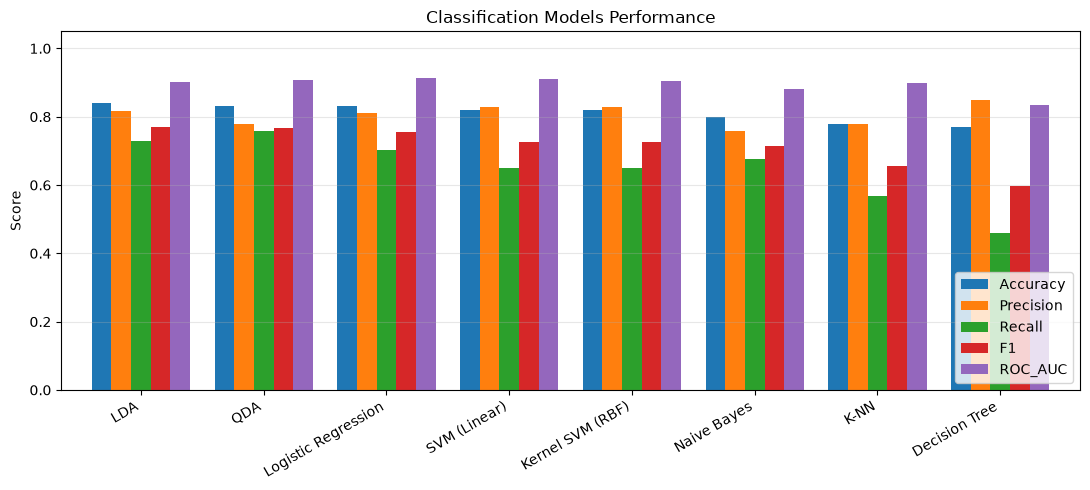

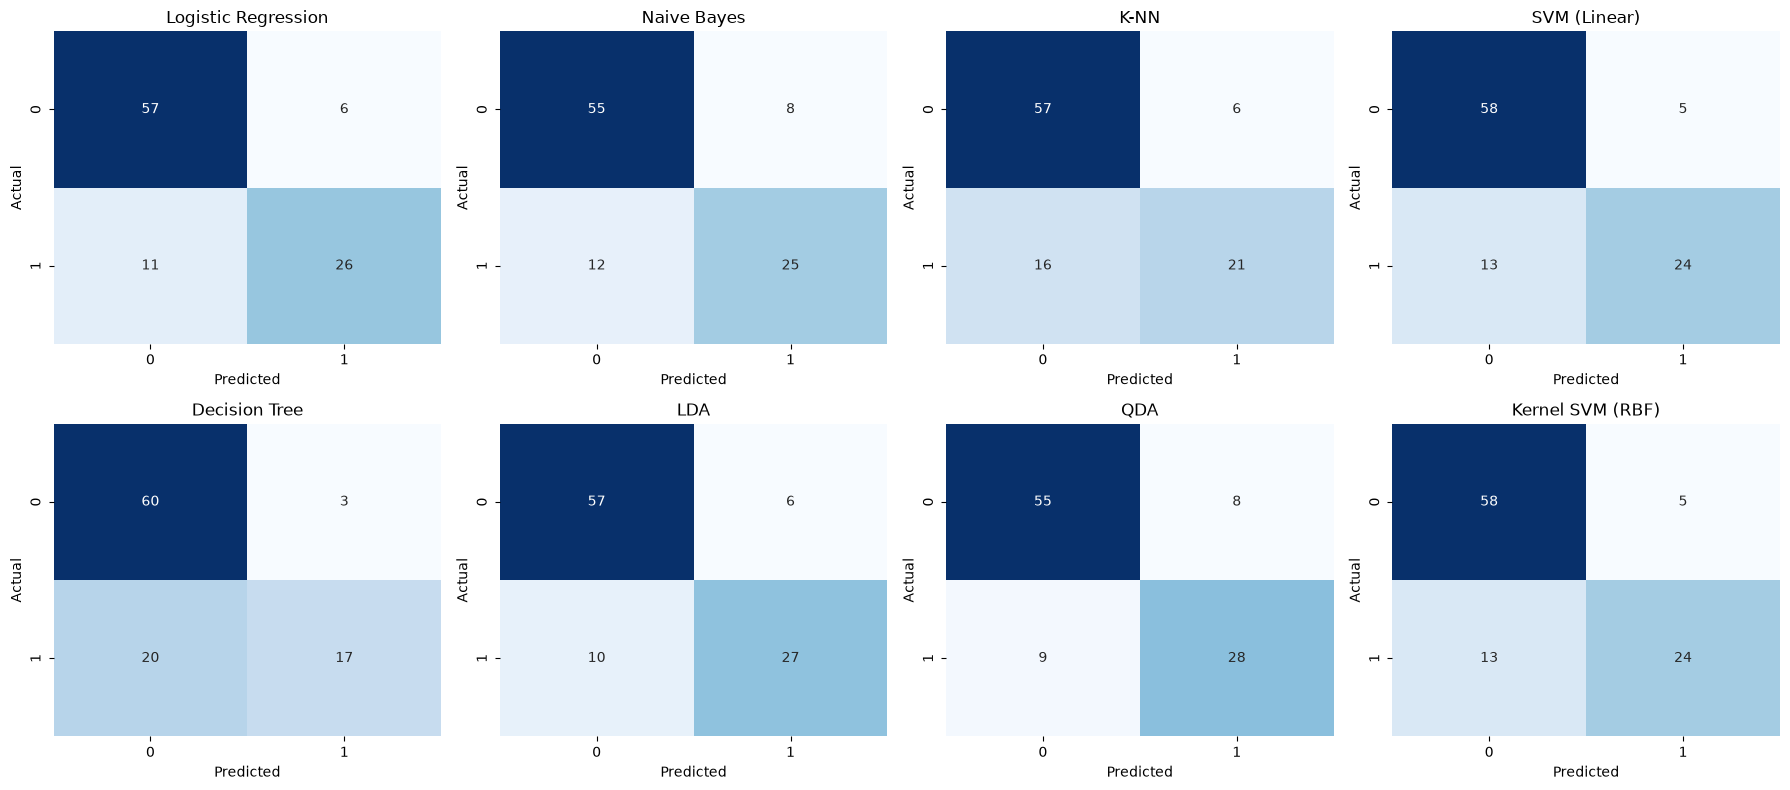

In [17]:
# Justification: accuracy alone can mislead on an imbalanced target (63% non-buyers),
# so we compare Precision, Recall, F1 and ROC-AUC side by side. Pick the model by
# F1 / ROC-AUC, and check CV accuracy against test accuracy for overfitting.
perf = pd.DataFrame(results).T.round(3).sort_values("F1", ascending=False)
print("\n================ MODEL PERFORMANCE COMPARISON ================")
print(perf)
print("\nBest model by F1:", perf.index[0])

perf[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]].plot(
    kind="bar", figsize=(11, 5), width=.8)
plt.title("Classification Models Performance"); plt.ylabel("Score"); plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right"); plt.legend(loc="lower right"); plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

# Confusion matrix heat-maps for all models
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fitted = {"Logistic Regression": (log_reg, X_test_sc), "Naive Bayes": (nb, X_test_sc),
          "K-NN": (knn, X_test_sc), "SVM (Linear)": (svm_linear, X_test_sc),
          "Decision Tree": (tree, X_test_imp), "LDA": (lda, X_test_sc),
          "QDA": (qda, X_test_sc), "Kernel SVM (RBF)": (kernel_svm, X_test_sc)}
for ax, (name, (m, Xte)) in zip(axes.ravel(), fitted.items()):
    sns.heatmap(confusion_matrix(y_test, m.predict(Xte)), annot=True, fmt="d",
                cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

# ROC_AUC

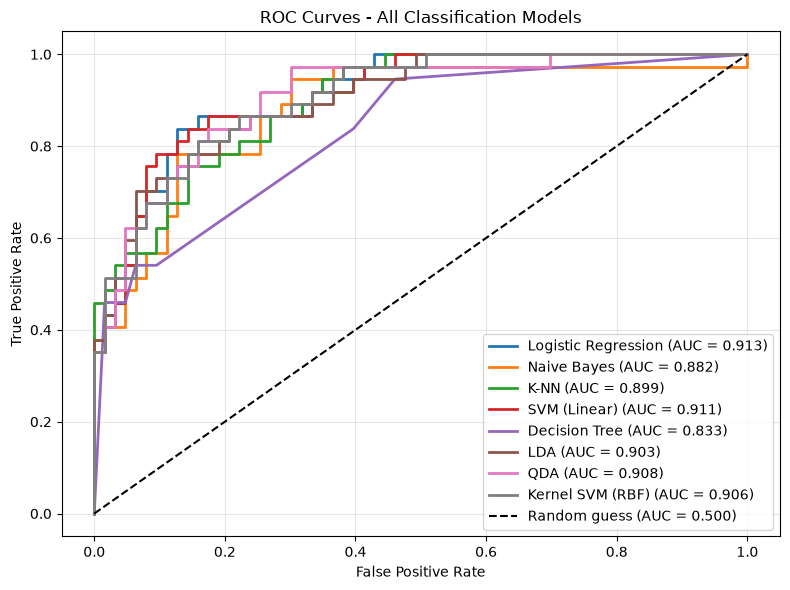

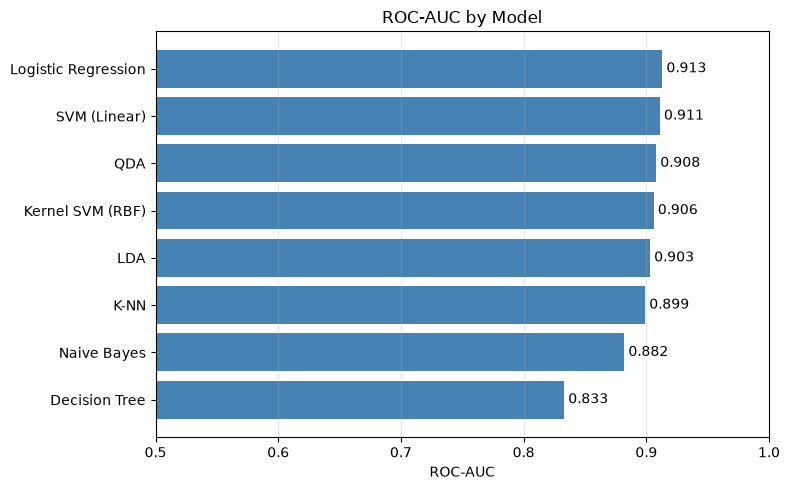

In [19]:
# ROC curves with AUC shown in the legend (all models on one graph)
# Justification: the ROC curve shows the trade-off between True Positive Rate and False
# Positive Rate at every threshold; AUC summarises it in one number (0.5 = random guess,
# 1.0 = perfect), and it does not depend on the 0.5 cut-off or on class imbalance.
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
plt.figure(figsize=(8, 6))
for name, (m, Xte) in fitted.items():
    score = m.predict_proba(Xte)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, score)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, score):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.500)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All Classification Models")
plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

# AUC ranking as a bar graph
auc_sorted = perf["ROC_AUC"].sort_values()
plt.figure(figsize=(8, 5))
bars = plt.barh(auc_sorted.index, auc_sorted.values, color="steelblue")
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.xlim(0.5, 1.0); plt.xlabel("ROC-AUC"); plt.title("ROC-AUC by Model")
plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()